# Signal and Model Discovery

Volatility forecasting (GARCH, Random Forest), pair cointegration and OU spreads, HMM regime detection.

The sample now runs from **January 2004 to August 2026**. The asset list is unchanged, but three of
the eight ETFs did not exist in 2004, so the price panel is *ragged*: each fund joins on its own
inception date. The next section shows exactly when each one arrives.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np  # Finite checks for OU visualization.
import pandas as pd

import src.models.volatility as vol_modeling  # Import as a module so autoreload updates the functions.
from src.models.ou import (
    compute_spread_zscore,
    estimate_ou_parameters,
    estimate_ou_parameters_exact_discrete,
    run_cointegration_test,
)
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes, summarize_regimes
from src.utils.config import DATA_CONFIG
from src.utils.data_loader import build_market_data_bundle, build_spread, make_volatility_features


## Load market data

Shared ETF universe; prices, log returns, and rolling realized volatility.


In [3]:
market_data = build_market_data_bundle()
prices = market_data.prices  # Keep the price table in a short variable name.
returns = market_data.log_returns
realized_vol = market_data.realized_volatility

prices.tail()


,EEM,EFA,FXE,GLD,SPY,TLT,USO,UUP
Date,,,,,,,,
2026-08-24,66.110001,108.029999,107.566689,426.690002,763.469971,82.244843,132.210007,27.959999
2026-08-25,67.250000,108.809998,107.716576,428.070007,765.909973,83.151375,126.150002,27.940001
2026-08-26,67.169998,108.269997,107.516724,421.320007,766.080017,82.982025,127.349998,28.020000
2026-08-27,67.610001,108.019997,107.456772,422.600006,771.099976,82.812668,130.009995,28.020000
2026-08-28,67.139999,107.720001,106.897209,408.890015,769.349976,82.563622,129.699997,28.180000


### When does each asset become available?

Starting in 2004 rather than 2014 buys the 2008 crisis, 2011 and 2015-16, which is what makes the
rest of this project worth reading. The cost is that GLD (Nov 2004), FXE (Dec 2005), USO (Apr 2006)
and UUP (Mar 2007) are missing at the start.

The loader keeps every date on which the benchmark trades and leaves younger assets missing until
they list. Every downstream calculation is written to tolerate that: a missing asset is excluded
from rankings and from weight normalization, and the backtest engine *raises an error* if any
strategy ever tries to hold a fund before its inception.

In [4]:
from src.utils.data_loader import asset_availability

availability = asset_availability(prices)
print(f"panel: {prices.shape[0]} rows from {prices.index.min().date()} to {prices.index.max().date()}")
availability

panel: 5700 rows from 2004-01-02 to 2026-08-28


,first_date,last_date,observations,share_of_sample
EEM,2004-01-02,2026-08-28,5700,1.0
EFA,2004-01-02,2026-08-28,5700,1.0
SPY,2004-01-02,2026-08-28,5700,1.0
TLT,2004-01-02,2026-08-28,5700,1.0
GLD,2004-11-18,2026-08-28,5478,0.961053
FXE,2005-12-12,2026-08-28,5210,0.914035
USO,2006-04-10,2026-08-28,5129,0.899825
UUP,2007-03-01,2026-08-28,4906,0.860702


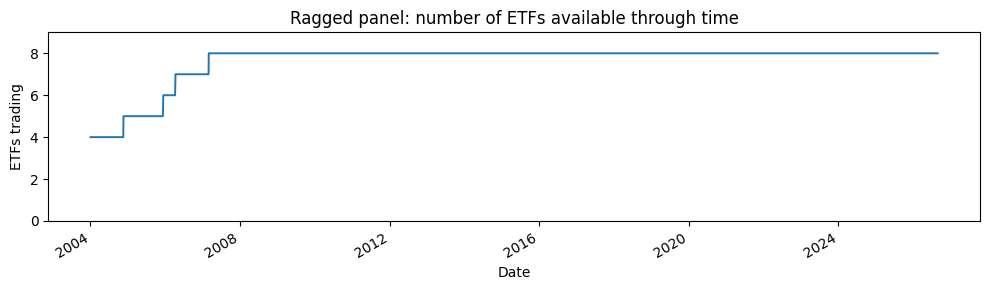

In [5]:
ax = prices.notna().sum(axis=1).plot(figsize=(10, 3), lw=1.4)
ax.set_ylim(0, 9)
ax.set_ylabel("ETFs trading")
ax.set_xlabel("Date")
ax.set_title("Ragged panel: number of ETFs available through time")
plt.tight_layout()
plt.show()

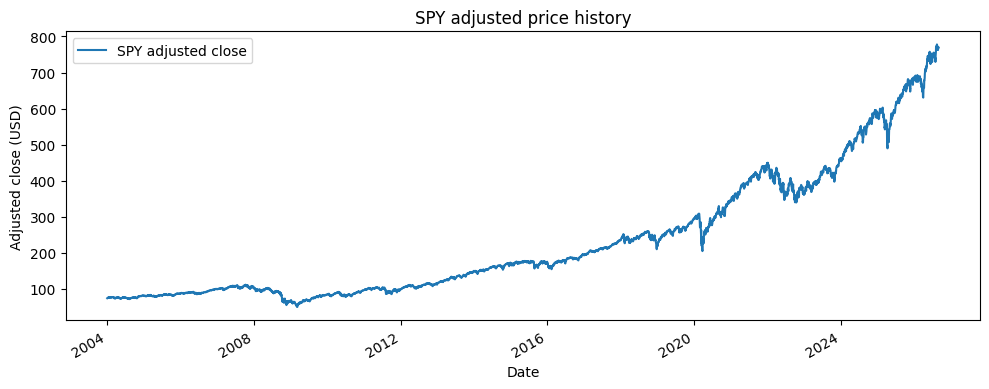

In [6]:
benchmark_prices = prices[DATA_CONFIG.benchmark_symbol]
benchmark_returns = returns[DATA_CONFIG.benchmark_symbol]
benchmark_realized_vol = realized_vol[DATA_CONFIG.benchmark_symbol].reindex(benchmark_returns.index)

ax_price = benchmark_prices.plot(figsize=(10, 4), title="SPY adjusted price history", label="SPY adjusted close")
ax_price.set_xlabel("Date")
ax_price.set_ylabel("Adjusted close (USD)")
ax_price.legend(loc="best")
plt.tight_layout()
plt.show()


## Step 2 - Forecast volatility

We compare two viewpoints:
- `GARCH(1,1)` says volatility clusters because today depends on yesterday's shock and yesterday's volatility.
- `RandomForest` says volatility may depend on several nonlinear lagged features.

At this stage we only judge forecast quality, not trading performance.

In [7]:
volatility_features = make_volatility_features(benchmark_returns, benchmark_realized_vol)  # Build lagged predictors and the next-period target.
train_features, test_features = vol_modeling.split_train_test(volatility_features)

rf_model = vol_modeling.fit_random_forest_volatility_model(train_features)
rf_prediction = vol_modeling.predict_random_forest_volatility(rf_model, test_features)
rf_metrics = vol_modeling.evaluate_forecasts(test_features["target_volatility"], rf_prediction)

pd.Series(rf_metrics, name="random_forest").to_frame()


,random_forest
mse,0.000254
mae,0.008365
correlation,0.990392


In [8]:
garch_fit = vol_modeling.fit_garch_model(benchmark_returns)  # Fit the GARCH model on the same benchmark return stream.
garch_volatility = vol_modeling.extract_garch_conditional_volatility(garch_fit, benchmark_returns.index)
garch_target = benchmark_realized_vol.reindex(garch_volatility.index)  # Align realized volatility with the GARCH output.
garch_metrics = vol_modeling.evaluate_forecasts(garch_target, garch_volatility)  # Evaluate how close GARCH is to realized volatility.

comparison = pd.DataFrame([rf_metrics, garch_metrics], index=["RandomForest", "GARCH"])
comparison


,mse,mae,correlation
RandomForest,0.000254,0.008365,0.990392
GARCH,0.031177,0.144291,0.954378


## Step 3 - Research statistical arbitrage pairs

Now we ask whether any pair of these ETFs moves together closely enough to support a
mean-reverting spread trade.

The original version of this project hard-coded one pair, EFA/EEM, and tested it. That is the wrong
shape of question: choosing a pair and then testing it invites the choice to be made with hindsight.
Instead we scan **all 28 unordered pairs**, and then ask two separate questions of the results:

1. does any pair show statistically credible cointegration, and
2. does cointegration have anything to do with whether a pair is *tradable*?

The workflow per pair is: build the spread, run an Engle-Granger cointegration test, estimate
Ornstein-Uhlenbeck mean reversion, and standardize the spread into a z-score.

### Scan every ETF pair in the universe

Scan all unordered pairs in `DATA_CONFIG.symbols` (OLS hedge, Engle-Granger, OU on the spread). Tickers are sorted alphabetically in pair labels (`EFA-EEM`).

`coint_5pct` is `True` when the test statistic is **more negative** than the 5% critical value (reject "no cointegration"). `half_life_days_*` uses \(\ln(2)/\kappa\) with \(\kappa\) from the exact discrete fit when it is finite; otherwise it is blank.

Because the panel is ragged, a pair is tested only on the dates when **both** ETFs traded. `overlap_days` reports how much history each test actually had, which matters when comparing a pair containing UUP (from 2007) against one containing only the four founding assets.


In [9]:
import itertools
import math


def _half_life_days(kappa: float) -> float:
    """OU-style half-life in days when kappa is a positive finite mean-reversion speed."""

    if kappa is None or not math.isfinite(kappa) or kappa <= 0:
        return float("nan")
    return math.log(2.0) / kappa


scan_rows: list[dict] = []
for asset_a, asset_b in itertools.combinations(sorted(DATA_CONFIG.symbols), 2):
    spread_frame = build_spread(prices[asset_a], prices[asset_b])
    spread = spread_frame["spread"]
    coint = run_cointegration_test(prices[asset_a], prices[asset_b])
    ou_ols = estimate_ou_parameters(spread, method="ols_delta")
    ou_ex = estimate_ou_parameters_exact_discrete(spread)
    scan_rows.append(
        {
            "pair": f"{asset_a}-{asset_b}",
            "eg_stat": coint["test_statistic"],
            "eg_pvalue": coint["p_value"],
            "eg_crit5": coint["critical_value_5pct"],
            "coint_5pct": bool(coint["test_statistic"] < coint["critical_value_5pct"]),
            # With a ragged panel two ETFs may share far less history than the sample
            # length, so the test's sample size belongs next to its p-value.
            "overlap_days": coint["overlapping_observations"],
            "kappa_exact": ou_ex["kappa"],
            "phi": ou_ex["phi"],
            "half_life_days_exact": _half_life_days(ou_ex["kappa"]),
            "kappa_ols": ou_ols["kappa"],
            "half_life_days_ols": _half_life_days(ou_ols["kappa"]),
        }
    )

pair_scan = (
    pd.DataFrame(scan_rows)
    .sort_values(["coint_5pct", "eg_pvalue"], ascending=[False, True])
    .reset_index(drop=True)
)
n_pass = int(pair_scan["coint_5pct"].sum())
print(f"Pairs rejecting no-cointegration at 5%: {n_pass} / {len(pair_scan)}")
winners = pair_scan.loc[pair_scan["coint_5pct"], "pair"].tolist()
if winners:
    print("Passing pairs (this ordering):", ", ".join(winners))
else:
    print("No pair passes the 5% cutoff with y/x = alphabetical ordering (try flipping dependent variable for borderline cases).")
pair_scan.round(6)


Pairs rejecting no-cointegration at 5%: 2 / 28
Passing pairs (this ordering): FXE-USO, EEM-GLD


,pair,eg_stat,eg_pvalue,eg_crit5,coint_5pct,overlap_days,kappa_exact,phi,half_life_days_exact,kappa_ols,half_life_days_ols
0,FXE-USO,-3.768738,0.014913,-3.337322,True,5129.0,0.004096,0.995912,169.222307,0.004088,1.695691e+02
1,EEM-GLD,-3.373036,0.045435,-3.337246,True,5478.0,0.005447,0.994567,127.242785,0.005433,1.275897e+02
2,EFA-SPY,-3.297099,0.055134,-3.337202,False,5700.0,0.004208,0.995801,164.740277,0.004199,1.650871e+02
3,SPY-UUP,-2.867656,0.145104,-3.337376,False,4906.0,0.004155,0.995853,166.804756,0.004147,1.671516e+02
4,FXE-TLT,-2.807192,0.163407,-3.337303,False,5210.0,0.002602,0.997401,266.355117,0.002599,2.667018e+02
5,EFA-UUP,-2.797004,0.166640,-3.337376,False,4906.0,0.004024,0.995985,172.273369,0.004015,1.726202e+02
6,EEM-SPY,-2.788220,0.169462,-3.337202,False,5700.0,0.003214,0.996792,215.695045,0.003208,2.160418e+02
7,EEM-EFA,-2.633987,0.224213,-3.337202,False,5700.0,0.002935,0.997070,236.182974,0.002930,2.365297e+02
8,TLT-USO,-2.412961,0.318741,-3.337322,False,5129.0,0.002323,0.997679,298.348220,0.002321,2.986949e+02
9,EFA-GLD,-2.401193,0.324290,-3.337246,False,5478.0,0.002531,0.997472,273.848243,0.002528,2.741950e+02


### How many passes should we expect by chance?

Two pairs reject the null of "no cointegration" at the 5% level. Before treating that as a
discovery, we have to account for the fact that we ran **28 tests**.

A test at the 5% level rejects a true null 5% of the time. Across 28 independent tests the expected
number of false rejections is therefore `28 x 0.05 = 1.4`, and the number of rejections follows a
Binomial(28, 0.05) distribution under the null that no pair is cointegrated.

The Bonferroni correction controls the family-wise error rate by dividing the significance level by
the number of tests: to claim 5% confidence across the whole scan, a single pair needs
`p < 0.05 / 28`.

In [10]:
from scipy.stats import binom

n_tests = len(pair_scan)
alpha = 0.05
n_passes = int(pair_scan["coint_5pct"].sum())

expected_false = n_tests * alpha
prob_at_least = 1.0 - binom.cdf(n_passes - 1, n_tests, alpha)
bonferroni = alpha / n_tests

print(f"pairs tested                              : {n_tests}")
print(f"pairs rejecting no-cointegration at 5%    : {n_passes}")
print(f"expected false rejections under the null  : {expected_false:.1f}")
print(f"P(at least {n_passes} passes | no pair is cointegrated) : {prob_at_least:.3f}")
print(f"Bonferroni-corrected threshold            : p < {bonferroni:.4f}")
print()
passers = pair_scan[pair_scan["coint_5pct"]][["pair", "eg_pvalue", "overlap_days", "half_life_days_exact"]]
print("The pairs that pass, and whether they survive the correction:")
for _, row in passers.iterrows():
    verdict = "survives" if row["eg_pvalue"] < bonferroni else "does NOT survive"
    print(f"  {row['pair']:8s} p={row['eg_pvalue']:.3f}  ->  {verdict} Bonferroni")

pairs tested                              : 28
pairs rejecting no-cointegration at 5%    : 2
expected false rejections under the null  : 1.4
P(at least 2 passes | no pair is cointegrated) : 0.412
Bonferroni-corrected threshold            : p < 0.0018

The pairs that pass, and whether they survive the correction:
  FXE-USO  p=0.015  ->  does NOT survive Bonferroni
  EEM-GLD  p=0.045  ->  does NOT survive Bonferroni


Two passes out of 28 is **exactly what chance produces**. The expected count under the null is 1.4,
and seeing two or more happens about 41% of the time even when no pair is cointegrated at all.
Neither pair comes close to the Bonferroni threshold.

So the scan gives us no statistically credible cointegrated pair. That is a real finding, not a
failure: on a universe of eight broad ETFs, there is no free stationary spread lying around.

### Does cointegration predict tradability?

The cointegration test asks a statistical question. Trading asks an economic one, after costs. It is
worth checking whether the two agree, because the whole justification for using the test as a filter
rests on the assumption that they do.

For every pair we build the z-score rule (enter at `|z| > 1.5`, exit at `|z| < 0.5`), run it through
the same backtest engine and cost model as every other strategy, and compare its net Sharpe ratio
against its cointegration p-value.

In [11]:
from src.backtest.engine import positions_to_strategy_returns, performance_metrics
from src.strategies.pairs_trading import pairs_positions_from_zscore
from src.utils.config import COST_CONFIG, PAIRS_CONFIG

TC, SLIP = COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps
simple_returns = market_data.simple_returns  # backtests use simple returns

tradability = []
for _, row in pair_scan.iterrows():
    leg_a, leg_b = row["pair"].split("-")
    spread = build_spread(prices[leg_a], prices[leg_b])["spread"]
    z = compute_spread_zscore(spread, window=PAIRS_CONFIG.zscore_window)
    bt = positions_to_strategy_returns(
        pairs_positions_from_zscore(z, leg_a, leg_b), simple_returns, TC, SLIP)
    tradability.append({
        "pair": row["pair"],
        "eg_pvalue": row["eg_pvalue"],
        "passes_5pct": row["coint_5pct"],
        "net_sharpe": performance_metrics(bt["net_return"])["sharpe_ratio"],
        "turnover_yr": bt["turnover"].mean() * 252,
    })

tradability = pd.DataFrame(tradability)
corr = tradability["eg_pvalue"].corr(tradability["net_sharpe"], method="spearman")
print(f"Spearman correlation between p-value and net Sharpe: {corr:+.3f}")
print("(a useful filter would be strongly NEGATIVE: low p-value should mean high Sharpe)")
print()
print("Best five pairs by net Sharpe:")
print(tradability.nlargest(5, "net_sharpe").round(3).to_string(index=False))
print()
print("The pairs that passed the cointegration test:")
print(tradability[tradability["passes_5pct"]].round(3).to_string(index=False))

Spearman correlation between p-value and net Sharpe: +0.322
(a useful filter would be strongly NEGATIVE: low p-value should mean high Sharpe)

Best five pairs by net Sharpe:
   pair  eg_pvalue  passes_5pct  net_sharpe  turnover_yr
EEM-USO      0.903        False       0.573       60.728
EFA-USO      0.982        False       0.411       57.387
SPY-USO      0.988        False       0.377       55.421
EEM-GLD      0.045         True       0.349       59.619
EEM-TLT      0.982        False       0.344       61.198

The pairs that passed the cointegration test:
   pair  eg_pvalue  passes_5pct  net_sharpe  turnover_yr
FXE-USO      0.015         True      -0.246       56.797
EEM-GLD      0.045         True       0.349       59.619


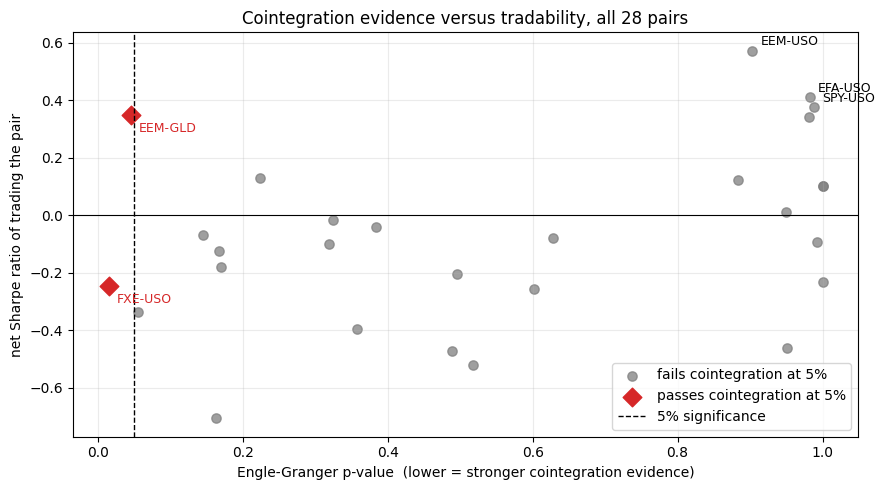

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
passed = tradability["passes_5pct"]
ax.scatter(tradability.loc[~passed, "eg_pvalue"], tradability.loc[~passed, "net_sharpe"],
           s=45, color="tab:gray", alpha=0.75, label="fails cointegration at 5%")
ax.scatter(tradability.loc[passed, "eg_pvalue"], tradability.loc[passed, "net_sharpe"],
           s=90, color="tab:red", marker="D", label="passes cointegration at 5%")
for _, row in tradability.nlargest(3, "net_sharpe").iterrows():
    ax.annotate(row["pair"], (row["eg_pvalue"], row["net_sharpe"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
for _, row in tradability[passed].iterrows():
    ax.annotate(row["pair"], (row["eg_pvalue"], row["net_sharpe"]),
                textcoords="offset points", xytext=(6, -12), fontsize=9, color="tab:red")
ax.axvline(0.05, color="black", ls="--", lw=1, label="5% significance")
ax.axhline(0.0, color="black", lw=0.8)
ax.set_xlabel("Engle-Granger p-value  (lower = stronger cointegration evidence)")
ax.set_ylabel("net Sharpe ratio of trading the pair")
ax.set_title("Cointegration evidence versus tradability, all 28 pairs")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### How should the spread be defined: price levels or log prices?

Everything above regressed price *levels*. That choice is worth questioning.

**Levels.** Regressing $P^{A}_t$ on $P^{B}_t$ gives

$$X_t \;=\; P^{A}_t - \alpha - \beta\,P^{B}_t .$$

Here $\beta$ carries units: it is *units of B per unit of A*, so its value depends on the price
levels themselves. If one asset triples over the sample while the other does not, the relationship
$\beta$ encodes changes even when the economic link is unchanged.

**Logs.** Regressing $\log P^{A}_t$ on $\log P^{B}_t$ gives

$$X_t \;=\; \log P^{A}_t - \alpha - \beta \log P^{B}_t .$$

Now $\beta$ is an *elasticity*: a 1% move in B corresponds to a $\beta$% move in A. That is
scale-free and stays interpretable as prices drift, and cointegration on $I(1)$ log prices is the
standard formulation in the literature.

The textbook argument for logs usually adds a third claim: that the log residual is closer to
**homoskedastic**, because a level residual inherits the price scale and so its variance should grow
as prices grow. That is the assumption the Engle-Granger test relies on. It is a testable claim, so
below we test it rather than repeat it.

In [13]:
from statsmodels.tsa.stattools import coint

spec_rows = []
for _, row in pair_scan.iterrows():
    leg_a, leg_b = row["pair"].split("-")
    frame = pd.concat([prices[leg_a], prices[leg_b]], axis=1).dropna()
    entry = {
        "pair": row["pair"],
        "p_levels": coint(frame.iloc[:, 0], frame.iloc[:, 1])[1],
        "p_logs": coint(np.log(frame.iloc[:, 0]), np.log(frame.iloc[:, 1]))[1],
    }
    # Homoskedasticity check: how much does the spread's own volatility move around?
    # A ratio near 1 would mean constant variance; large means strongly heteroskedastic.
    for use_log, key in [(False, "levels"), (True, "logs")]:
        rolling_sd = build_spread(prices[leg_a], prices[leg_b],
                                  use_log=use_log)["spread"].rolling(252).std().dropna()
        entry[f"volratio_{key}"] = rolling_sd.max() / rolling_sd.min()
    spec_rows.append(entry)
spec = pd.DataFrame(spec_rows)

print("Cointegration evidence")
print(f"  pairs passing at 5%   levels: {(spec['p_levels'] < 0.05).sum()}   "
      f"logs: {(spec['p_logs'] < 0.05).sum()}")
print(f"  median p-value        levels: {spec['p_levels'].median():.3f}   "
      f"logs: {spec['p_logs'].median():.3f}")
print()
print("Homoskedasticity: rolling 1-year spread volatility, max/min ratio (1.0 = constant variance)")
print(f"  median across pairs   levels: {spec['volratio_levels'].median():.2f}x   "
      f"logs: {spec['volratio_logs'].median():.2f}x")
print(f"  logs more stable in {(spec['volratio_logs'] < spec['volratio_levels']).sum()} "
      f"of {len(spec)} pairs")
print()
print("Pairs passing under either specification:")
print(spec[(spec.p_levels < 0.05) | (spec.p_logs < 0.05)][
    ["pair", "p_levels", "p_logs"]].round(3).to_string(index=False))

Cointegration evidence
  pairs passing at 5%   levels: 2   logs: 2
  median p-value        levels: 0.507   logs: 0.390

Homoskedasticity: rolling 1-year spread volatility, max/min ratio (1.0 = constant variance)
  median across pairs   levels: 11.14x   logs: 11.29x
  logs more stable in 15 of 28 pairs

Pairs passing under either specification:
   pair  p_levels  p_logs
FXE-USO     0.015   0.022
EEM-GLD     0.045   0.027


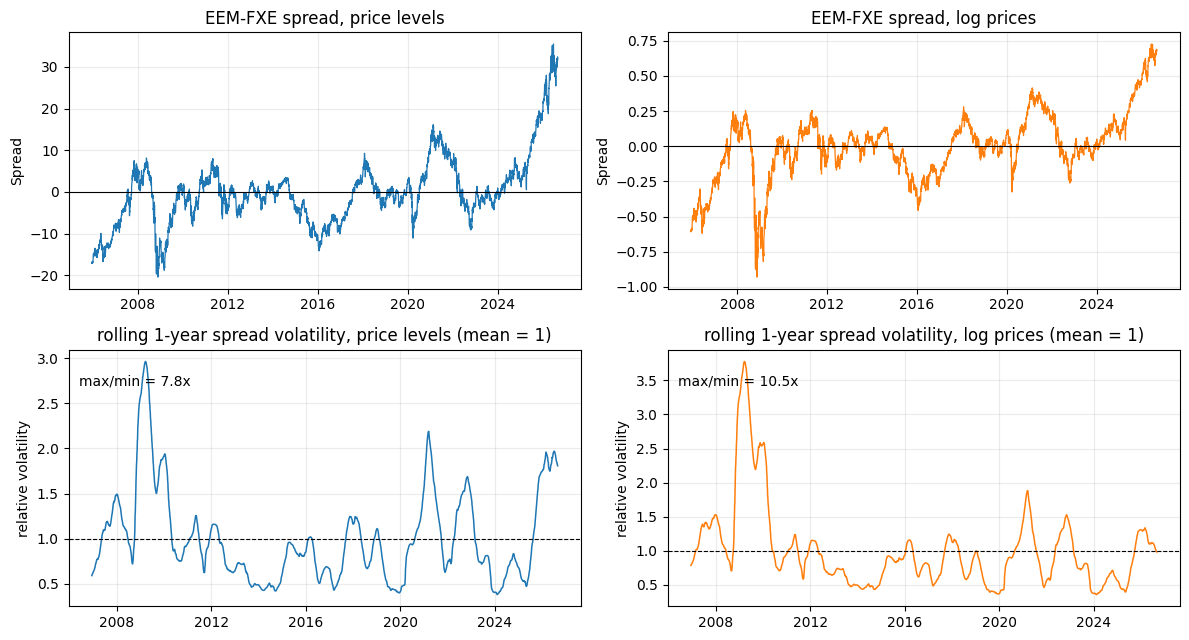

In [14]:
# The heteroskedasticity argument, made visible on one pair. Note the max/min
# annotations: taking logs does not flatten the volatility of this spread.
leg_a, leg_b = "EEM", "FXE"
frame = pd.concat([prices[leg_a], prices[leg_b]], axis=1).dropna()

spread_levels = build_spread(prices[leg_a], prices[leg_b], use_log=False)["spread"]
spread_logs = build_spread(prices[leg_a], prices[leg_b], use_log=True)["spread"]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for col, (series, name) in enumerate([(spread_levels, "price levels"), (spread_logs, "log prices")]):
    axes[0, col].plot(series, lw=0.9, color="tab:blue" if col == 0 else "tab:orange")
    axes[0, col].axhline(0, color="black", lw=0.8)
    axes[0, col].set_title(f"{leg_a}-{leg_b} spread, {name}")
    axes[0, col].set_ylabel("Spread")
    # Rolling standard deviation: a homoskedastic residual should look flat.
    rolling_sd = series.rolling(252).std()
    axes[1, col].plot(rolling_sd / rolling_sd.mean(), lw=1.1,
                      color="tab:blue" if col == 0 else "tab:orange")
    axes[1, col].axhline(1.0, color="black", ls="--", lw=0.8)
    axes[1, col].set_title(f"rolling 1-year spread volatility, {name} (mean = 1)")
    axes[1, col].set_ylabel("relative volatility")
    ratio = rolling_sd.max() / rolling_sd.min()
    axes[1, col].annotate(f"max/min = {ratio:.1f}x", xy=(0.02, 0.86),
                          xycoords="axes fraction", fontsize=10)
for ax in axes.flat:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**The theory is half right.**

The cointegration evidence does improve: the median p-value across the 28 pairs falls from about
0.51 on levels to about 0.39 on logs, though the same two pairs pass at 5% either way.

The homoskedasticity claim does **not** survive contact with the data. The spread's rolling
volatility swings by a factor of roughly 11 under both specifications, and logs are the more stable
choice in only about half the pairs, which is a coin flip. The plot above shows why: these spreads'
variance is driven by market-wide volatility regimes, 2008 above all, and not by the price level.
Taking logs removes a scale effect that was never the dominant source of heteroskedasticity here.

So logs remain the better-founded specification on the grounds that survive scrutiny, namely a
scale-free hedge ratio and the standard treatment of $I(1)$ prices, and they do produce modestly
stronger cointegration evidence. Notebook 2 asks whether that carries over to trading, and finds it
does not, which turns out to say more about the strategy than about the specification.

The scatter shows there is no usable relationship. The two pairs that pass the test sit at opposite
ends of the performance range, and several of the best-performing pairs have p-values near 1.0, that
is, no cointegration evidence whatsoever.

**So what should the pairs strategy actually trade?**

Not a pair picked from this table. Selecting the best-performing pair after seeing all 28 results is
the same hindsight error as hard-coding one in advance, only better disguised: the number that came
out of the search is not the number a trader would have earned, because a trader in 2006 could not
have run this search.

The honest answer is to make the pair a **parameter that the walk-forward chooses**. In notebook 2,
on each fold, every eligible pair is scored on its training window only and the winner is traded on
the following test block. Each pair's hedge ratio is already refit per fold, so this adds an outer
layer of walk-forward rather than reintroducing hindsight.

Below we look at the OU fit and spread dynamics of the pair the walk-forward ends up trading most.

In [15]:
# The pair the walk-forward selected most often (see notebook 2); fall back to the
# best-scanned pair if the pipeline has not been run yet.
choices_path = project_root / "results" / "cache" / "wf_parameter_choices.csv"
if choices_path.exists():
    chosen = pd.read_csv(choices_path, index_col=0)["pairs_trading"].dropna()
    asset_a, asset_b = chosen.value_counts().index[0].split("-")
    print(f"most-selected pair in the walk-forward: {asset_a}-{asset_b} "
          f"({chosen.value_counts(normalize=True).iloc[0]:.0%} of folds)")
else:
    asset_a, asset_b = tradability.nlargest(1, "net_sharpe")["pair"].iloc[0].split("-")
    print(f"pipeline not run yet; showing best-scanned pair {asset_a}-{asset_b}")

spread_frame = build_spread(prices[asset_a], prices[asset_b])
cointegration_result = run_cointegration_test(prices[asset_a], prices[asset_b])
ou_result = estimate_ou_parameters(spread_frame["spread"], method="ols_delta")
ou_exact = estimate_ou_parameters_exact_discrete(spread_frame["spread"])
spread_zscore = compute_spread_zscore(spread_frame["spread"], window=PAIRS_CONFIG.zscore_window)

pd.concat([
    pd.Series(cointegration_result),
    pd.Series(ou_result).rename(index=lambda k: f"ou_ols_delta.{k}"),
    pd.Series(ou_exact).rename(index=lambda k: f"ou_exact_discrete.{k}"),
]).to_frame(name="value")

most-selected pair in the walk-forward: EEM-FXE (47% of folds)


,value
test_statistic,-1.095519
p_value,0.883183
critical_value_5pct,-3.337303
overlapping_observations,5210.000000
ou_ols_delta.alpha,0.009372
ou_ols_delta.beta,-0.001501
ou_ols_delta.kappa,0.001501
ou_ols_delta.long_run_mean,6.245155
ou_ols_delta.residual_volatility,0.588078
ou_exact_discrete.kappa,0.001502


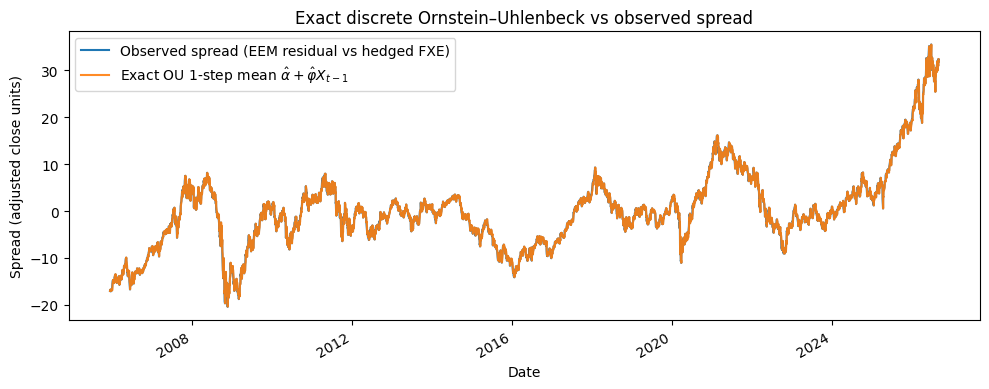

In [16]:
# Visualize the exact discrete OU fit: conditional mean E[X_t | X_{t-1}] = α̂ + φ̂ X_{t-1} (same as θ̂(1-φ̂) + φ̂ X_{t-1}).
spread_obs = spread_frame["spread"].dropna()
phi_hat = ou_exact["phi"]
alpha_hat = ou_exact["ar1_intercept"]
if np.isfinite(phi_hat) and np.isfinite(alpha_hat) and 0.0 < phi_hat < 1.0:
    spread_ou_mean = alpha_hat + phi_hat * spread_obs.shift(1)  # One-step OU/AR(1) prediction aligned on spread_obs index.
else:
    spread_ou_mean = pd.Series(np.nan, index=spread_obs.index)

fig_ou, ax_ou = plt.subplots(figsize=(10, 4))
spread_obs.plot(ax=ax_ou, label=f"Observed spread ({asset_a} residual vs hedged {asset_b})", color="C0")
spread_ou_mean.plot(ax=ax_ou, label=r"Exact OU 1-step mean $\hat{\alpha}+\hat{\varphi}X_{t-1}$", color="C1", alpha=0.9)
ax_ou.set_title("Exact discrete Ornstein–Uhlenbeck vs observed spread")
ax_ou.set_xlabel("Date")
ax_ou.set_ylabel("Spread (adjusted close units)")
ax_ou.legend(loc="best")
plt.tight_layout()
plt.show()

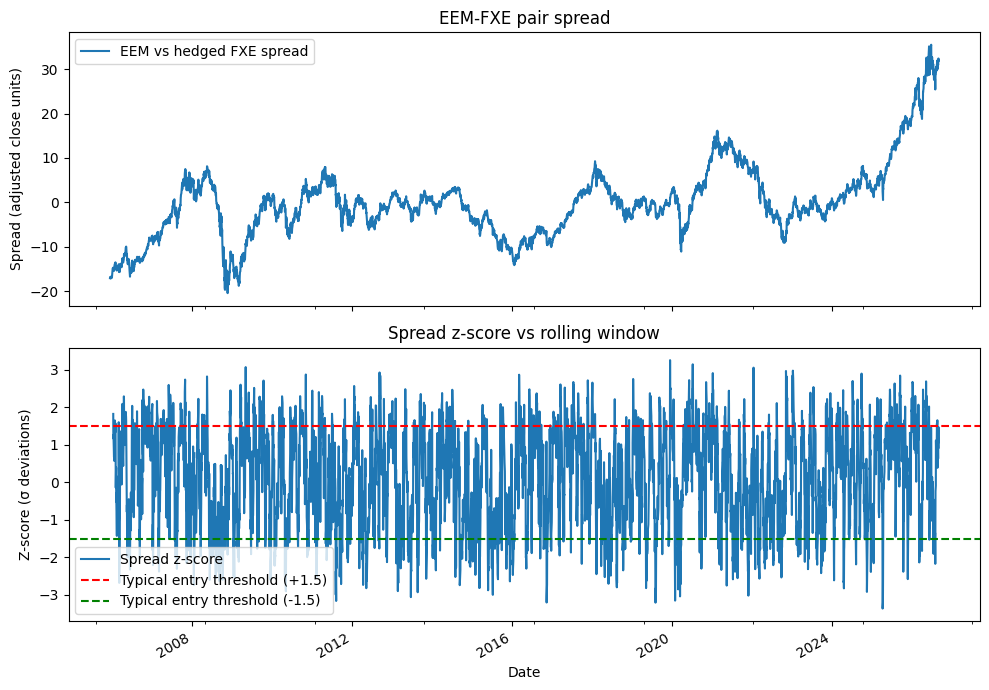

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
spread_frame["spread"].plot(ax=axes[0], title=f"{asset_a}-{asset_b} pair spread", label=f"{asset_a} vs hedged {asset_b} spread")
spread_zscore.plot(ax=axes[1], title="Spread z-score vs rolling window", label="Spread z-score")
axes[1].axhline(1.5, color="red", linestyle="--", label="Typical entry threshold (+1.5)")
axes[1].axhline(-1.5, color="green", linestyle="--", label="Typical entry threshold (-1.5)")
axes[0].set_ylabel("Spread (adjusted close units)")
axes[0].legend(loc="best")
axes[1].set_ylabel("Z-score (σ deviations)")
axes[1].set_xlabel("Date")
axes[1].legend(loc="best")
plt.tight_layout()
plt.show()


## Step 4 - Infer hidden market regimes

The HMM does not directly tell us labels such as `bull` or `crisis`.

Instead, it finds latent states that explain patterns in returns and volatility. We interpret those states after estimation by looking at their average behavior.

In [18]:
regime_features = build_regime_features(benchmark_returns, benchmark_realized_vol)
hmm_model = fit_hmm_regime_model(regime_features)
regimes = infer_regimes(hmm_model, regime_features)
regime_summary = summarize_regimes(regime_features, regimes)

regime_summary


returns                 realized_volatility                  \
            mean       std count                mean       std count   
regime                                                                 
0       0.000300  0.010425  2510            0.160261  0.033985  2510   
1       0.000754  0.005515  2469            0.088724  0.018608  2469   
2      -0.000417  0.024997   700            0.363898  0.170002   700   

        momentum                  
            mean       std count  
regime                            
0       0.000040  0.001777  2510  
1       0.001217  0.000934  2469  
2      -0.001117  0.004468   700

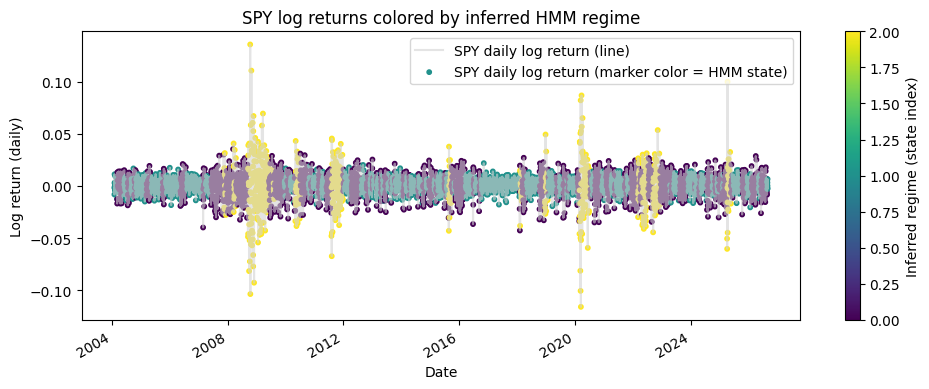

In [19]:
regime_plot_frame = pd.DataFrame({"returns": benchmark_returns.reindex(regimes.index), "regime": regimes})

fig, ax = plt.subplots(figsize=(10, 4))
regime_plot_frame["returns"].plot(ax=ax, color="lightgray", alpha=0.6, label="SPY daily log return (line)")  # Plot the raw return series in the background.
sc_reg = ax.scatter(
    regime_plot_frame.index,
    regime_plot_frame["returns"],
    c=regime_plot_frame["regime"],
    cmap="viridis",
    s=10,
    label="SPY daily log return (marker color = HMM state)",
)
ax.set_title("SPY log returns colored by inferred HMM regime")
ax.set_xlabel("Date")
ax.set_ylabel("Log return (daily)")
ax.legend(loc="best")
fig.colorbar(sc_reg, ax=ax, label="Inferred regime (state index)")
plt.tight_layout()
plt.show()


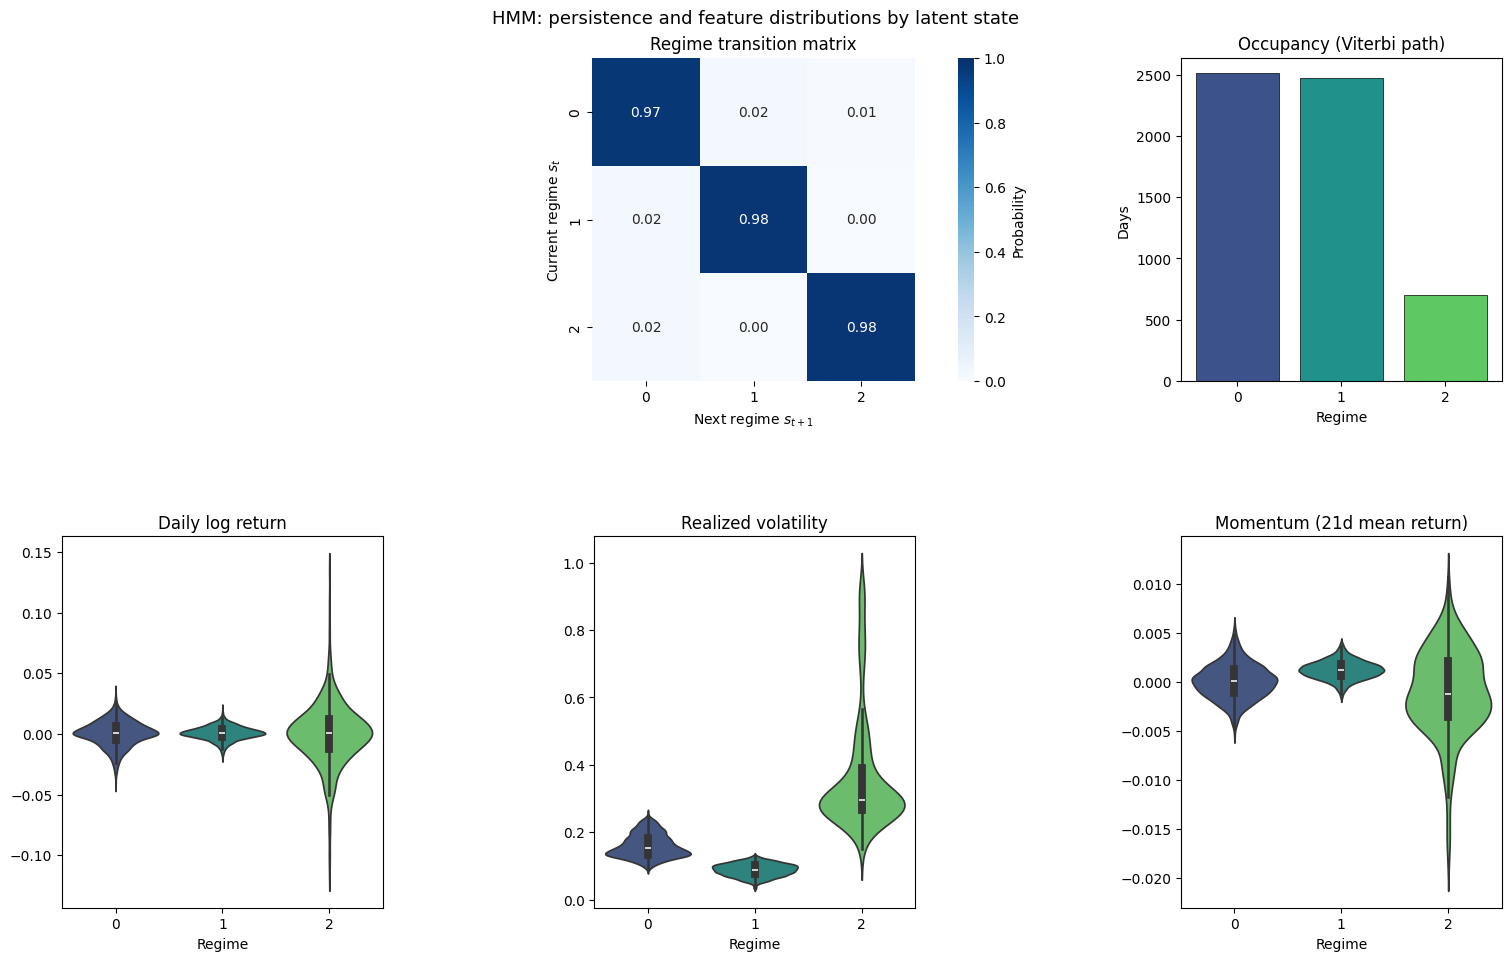

In [20]:
import seaborn as sns

viz_df = regime_features.copy()
viz_df["regime"] = regimes.astype(str)
n_states = hmm_model.n_components
order = [str(i) for i in range(n_states)]

fig = plt.figure(figsize=(15, 9.5), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 1.15], hspace=0.18, wspace=0.18)
pal = sns.color_palette("viridis", n_states)

ax_tm = fig.add_subplot(gs[0, :2])
sns.heatmap(
    hmm_model.transmat_,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=ax_tm,
    xticklabels=order,
    yticklabels=order,
    cbar_kws={"label": "Probability"},
)
ax_tm.set_xlabel(r"Next regime $s_{t+1}$")
ax_tm.set_ylabel(r"Current regime $s_t$")
ax_tm.set_title("Regime transition matrix")

ax_occ = fig.add_subplot(gs[0, 2])
occ = regimes.value_counts().reindex(range(n_states), fill_value=0)
ax_occ.bar(order, occ.values, color=pal, edgecolor="black", linewidth=0.5)
ax_occ.set_xlabel("Regime")
ax_occ.set_ylabel("Days")
ax_occ.set_title("Occupancy (Viterbi path)")

panels = [
    ("returns", "Daily log return"),
    ("realized_volatility", "Realized volatility"),
    ("momentum", "Momentum (21d mean return)"),
]
for col, (key, title) in enumerate(panels):
    ax = fig.add_subplot(gs[1, col])
    sns.violinplot(
        data=viz_df,
        x="regime",
        y=key,
        order=order,
        hue="regime",
        hue_order=order,
        inner="box",
        palette=pal,
        ax=ax,
        legend=False,
        dodge=False,
    )
    ax.set_title(title)
    ax.set_xlabel("Regime")
    ax.set_ylabel("")

fig.suptitle("HMM: persistence and feature distributions by latent state", fontsize=13)
plt.show()